In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"D:\DS\MiniProjects\Content Monetization Modeler\youtube_ad_revenue_dataset.csv")

In [3]:
df.head()

,video_id,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd
0,vid_3092,2024-09-24 10:50:40.993199,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237
1,vid_3459,2024-09-22 10:50:40.993199,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508
2,vid_4784,2024-11-21 10:50:40.993199,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008
3,vid_4078,2025-01-28 10:50:40.993199,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261
4,vid_3522,2025-04-28 10:50:40.993199,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388


In [4]:
df.tail()

,video_id,date,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd
122395,vid_2902,2024-12-14 10:50:40.993199,9853,1673.0,147.0,42075.704885,25.490195,210818,Education,Tablet,US,280.986396
122396,vid_3890,2024-07-13 10:50:40.993199,10128,1709.0,63.0,57563.703040,16.229133,878860,Music,Desktop,UK,354.612981
122397,vid_3934,2024-06-10 10:50:40.993199,10267,700.0,NaN,27549.714659,23.822365,576756,Tech,Tablet,CA,203.643106
122398,vid_4260,2024-12-22 10:50:40.993199,10240,1616.0,106.0,56967.384382,7.753099,585138,Music,Mobile,UK,351.525811
122399,vid_1056,2024-06-25 10:50:40.993199,9931,770.0,NaN,38466.837135,27.305703,517587,Tech,TV,CA,253.842824


In [5]:
df.shape

(122400, 12)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 122400 entries, 0 to 122399
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   video_id              122400 non-null  str    
 1   date                  122400 non-null  str    
 2   views                 122400 non-null  int64  
 3   likes                 116283 non-null  float64
 4   comments              116288 non-null  float64
 5   watch_time_minutes    116295 non-null  float64
 6   video_length_minutes  122400 non-null  float64
 7   subscribers           122400 non-null  int64  
 8   category              122400 non-null  str    
 9   device                122400 non-null  str    
 10  country               122400 non-null  str    
 11  ad_revenue_usd        122400 non-null  float64
dtypes: float64(5), int64(2), str(5)
memory usage: 11.2 MB


In [7]:
df.describe()

,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,ad_revenue_usd
count,122400.000000,116283.000000,116288.000000,116295.000000,122400.000000,122400.000000,122400.000000
mean,9999.856283,1099.633618,274.396636,37543.827721,16.014165,502191.719902,252.727210
std,99.881260,519.424089,129.741739,12987.724246,8.083790,288397.470103,61.957052
min,9521.000000,195.000000,48.000000,14659.105562,2.000142,1005.000000,126.590603
25%,9933.000000,650.000000,162.000000,26366.320569,9.004695,252507.500000,199.902018
50%,10000.000000,1103.000000,274.000000,37531.990337,16.005906,503465.500000,252.749699
75%,10067.000000,1547.000000,387.000000,48777.782090,23.021260,752192.000000,305.597518
max,10468.000000,2061.000000,515.000000,61557.670089,29.999799,999997.000000,382.768254


Removing the 'video_id' column from the dataframe because this column will have no effect on revenue generation.

In [8]:
df.drop('video_id', axis=1, inplace=True)

In [9]:
df.shape

(122400, 11)

__Checking for missing values in the dataset and handling them__

In [10]:
100*df.isnull().sum()/df.shape[0]

date                    0.000000
views                   0.000000
likes                   4.997549
comments                4.993464
watch_time_minutes      4.987745
video_length_minutes    0.000000
subscribers             0.000000
category                0.000000
device                  0.000000
country                 0.000000
ad_revenue_usd          0.000000
dtype: float64

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

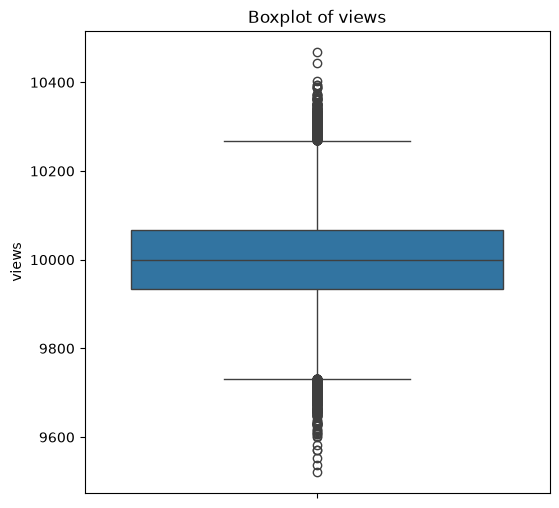

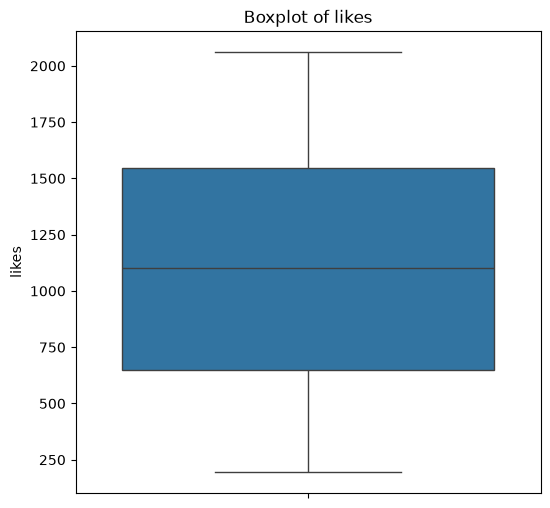

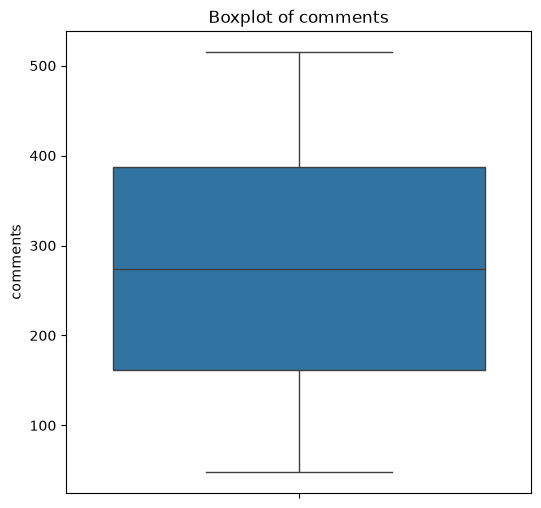

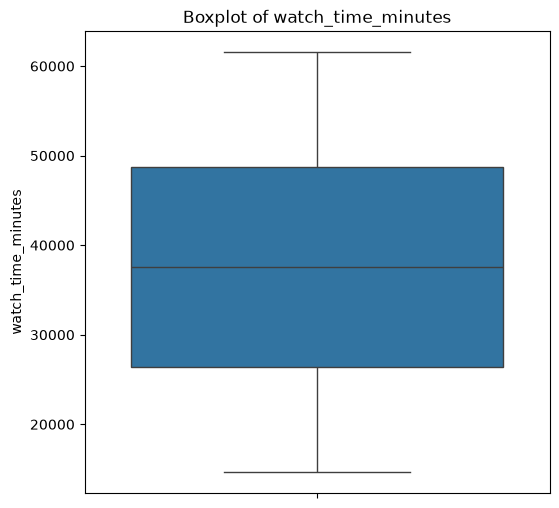

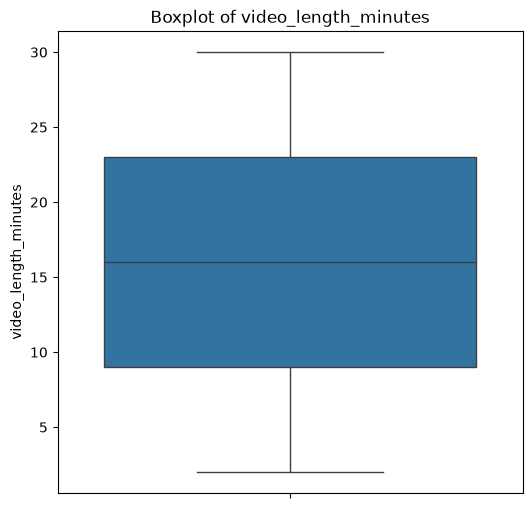

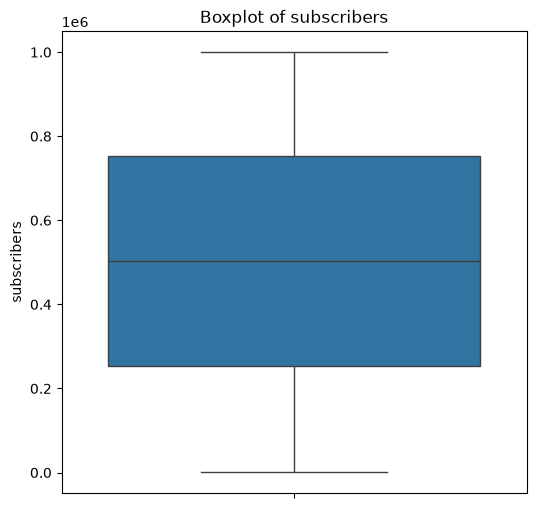

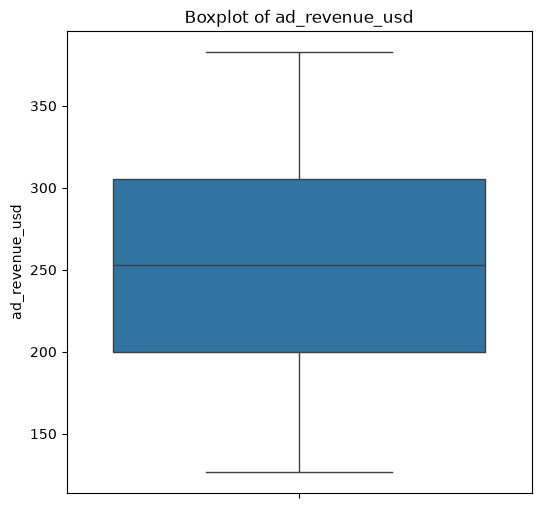

In [12]:
numerical_columns = [
    'views',
    'likes',
    'comments',
    'watch_time_minutes',
    'video_length_minutes',
    'subscribers',
    'ad_revenue_usd'
]

for col in numerical_columns:
    plt.figure(figsize=(6,6))
    sns.boxplot(df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

As we can see from the Boxplots, the 'Views' column has Outliers that need to be handled.

**OUTLIER HANDLING**

In [13]:
Q1 = df['views'].quantile(0.25)
Q3 = df['views'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR
df1 = df[(df['views']>=lower_bound) & (df['views']<=upper_bound)]

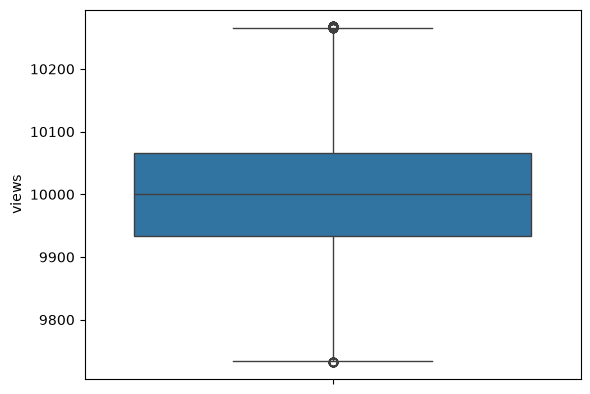

In [14]:
sns.boxplot(df1['views'])
plt.show()

In [15]:
print("New min views:", df1['views'].min())
print("New max views:", df1['views'].max())
print("Calculated lower bound:", lower_bound)
print("Calculated upper bound:", upper_bound)

New min views: 9732
New max views: 10268
Calculated lower bound: 9732.0
Calculated upper bound: 10268.0


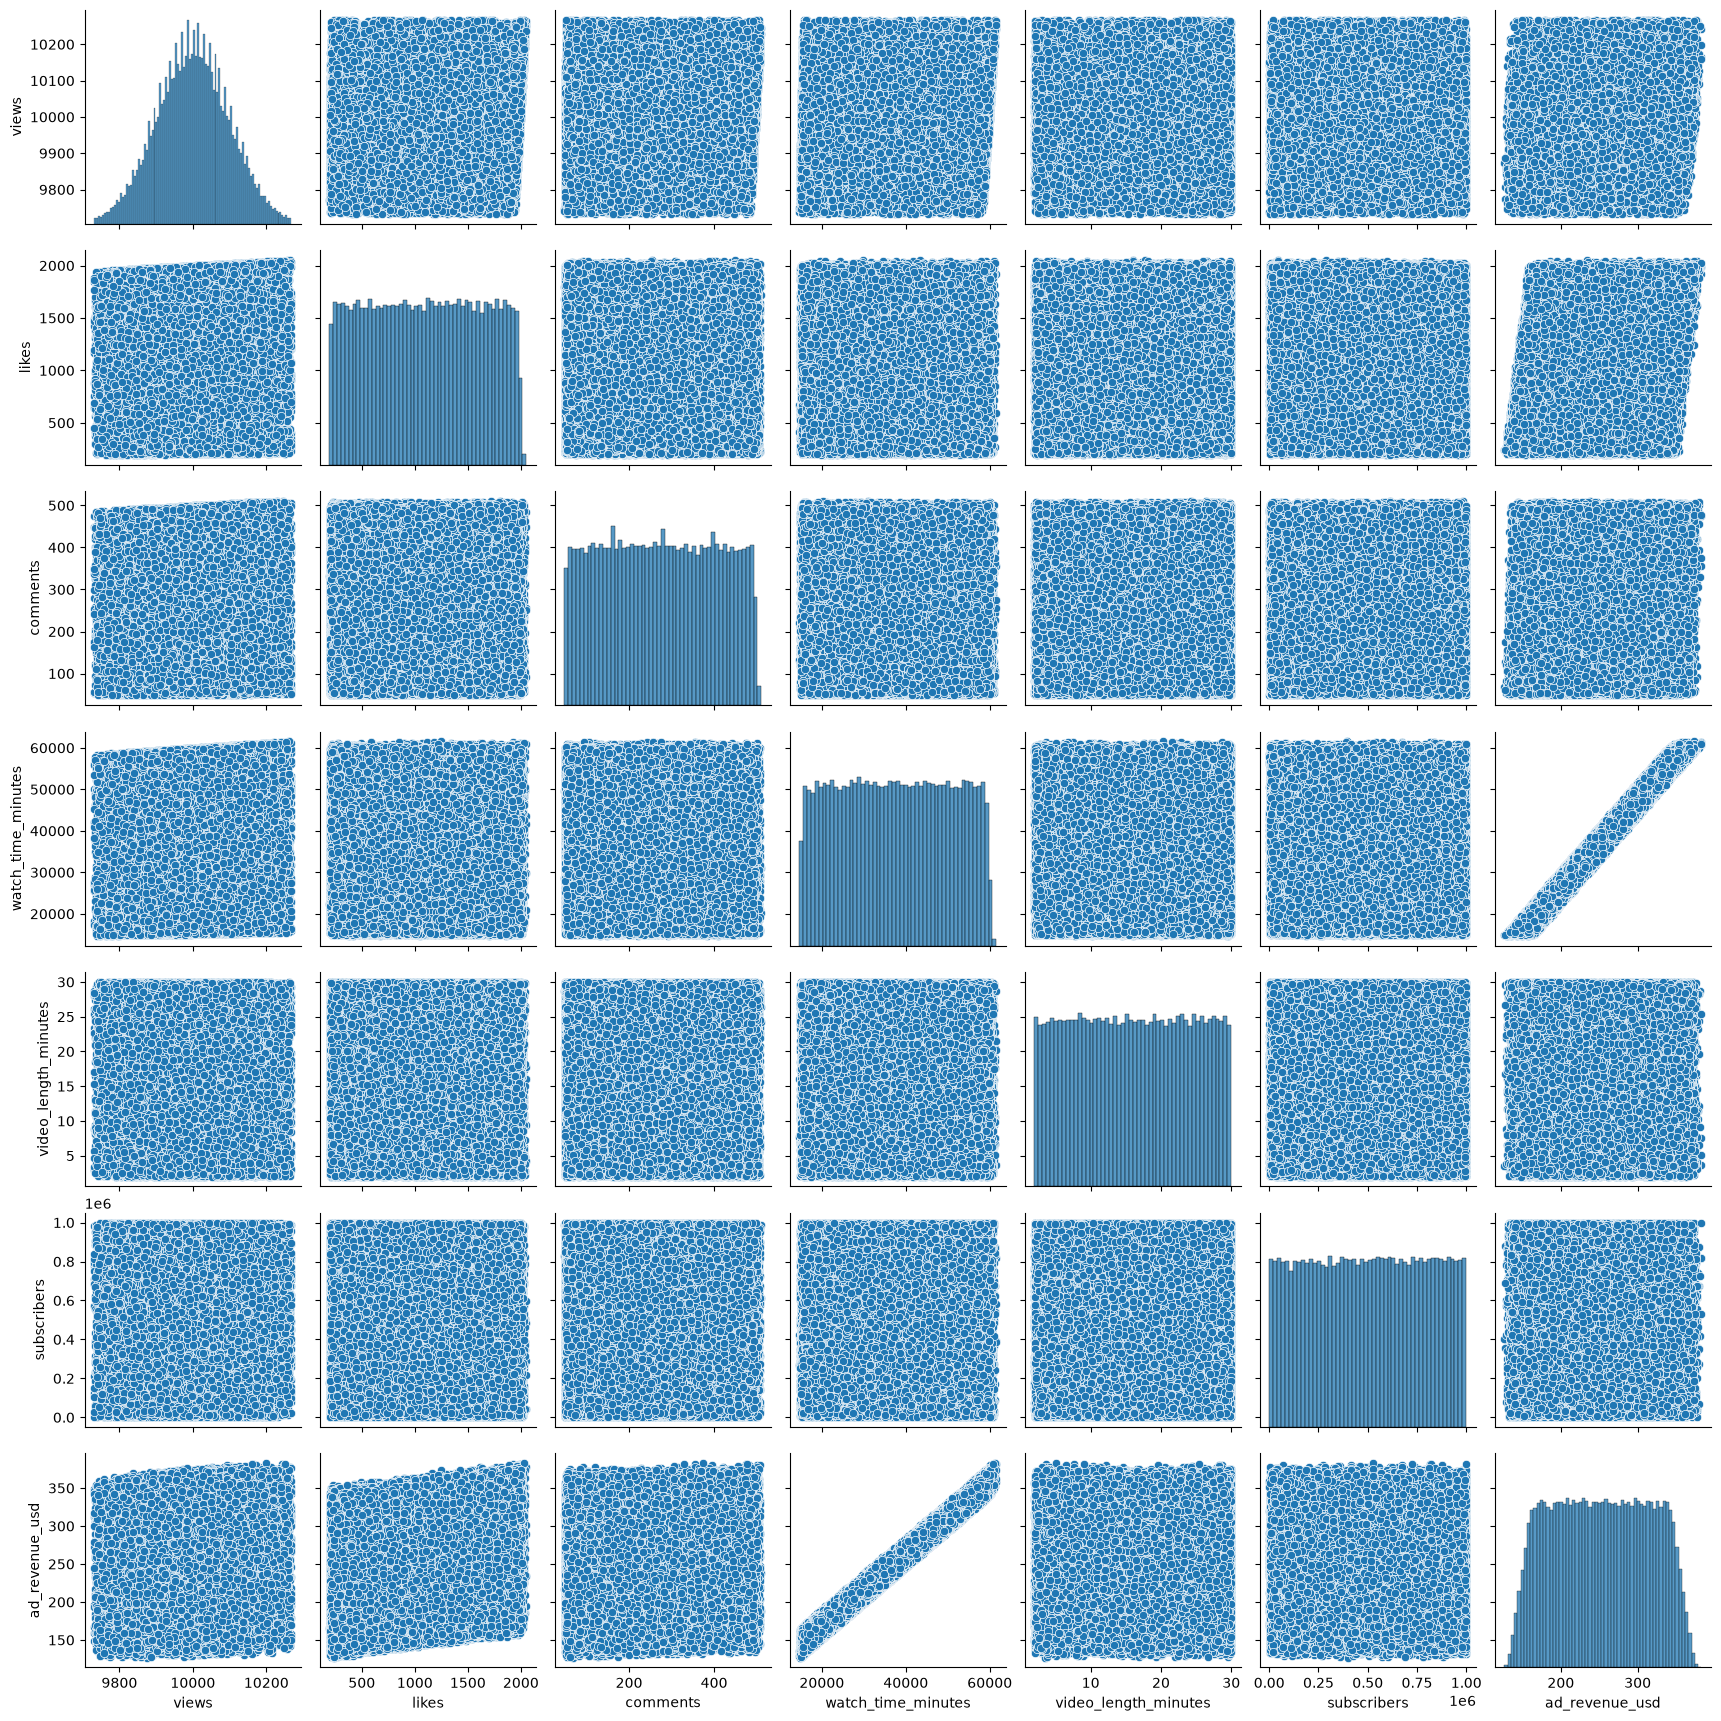

In [16]:
sns.pairplot(df1)

In [17]:
df1[numerical_columns].corr()

,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,ad_revenue_usd
views,1.000000,0.015253,0.018219,0.025896,-0.001004,0.001468,0.036768
likes,0.015253,1.000000,-0.002189,0.002591,0.000714,0.003760,0.146016
comments,0.018219,-0.002189,1.000000,-0.000587,-0.002454,-0.000807,0.034727
watch_time_minutes,0.025896,0.002591,-0.000587,1.000000,-0.001132,0.005503,0.988878
video_length_minutes,-0.001004,0.000714,-0.002454,-0.001132,1.000000,0.002482,-0.000736
subscribers,0.001468,0.003760,-0.000807,0.005503,0.002482,1.000000,0.005989
ad_revenue_usd,0.036768,0.146016,0.034727,0.988878,-0.000736,0.005989,1.000000


<Axes: >

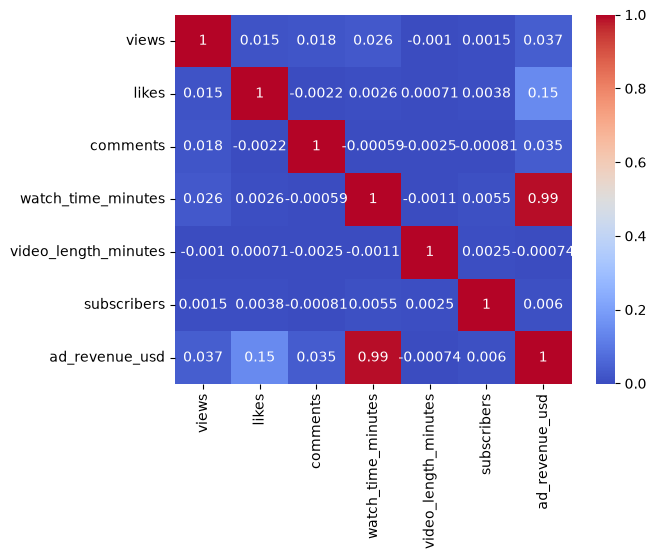

In [18]:
sns.heatmap(df1[numerical_columns].corr(), annot=True, cmap='coolwarm')

Since the dependancy is only between an input feature and an output feature, it is not being handled here. 

In [19]:
100*df1.isnull().sum()/df1.shape[0]

date                    0.000000
views                   0.000000
likes                   4.990866
comments                5.003209
watch_time_minutes      4.985928
video_length_minutes    0.000000
subscribers             0.000000
category                0.000000
device                  0.000000
country                 0.000000
ad_revenue_usd          0.000000
dtype: float64

In [20]:
df1['likes'] = df1['likes'].fillna(df1['likes'].median())
df1['comments'] = df1['comments'].fillna(df1['comments'].median())
df1['watch_time_minutes'] = df1['watch_time_minutes'].fillna(df1['watch_time_minutes'].median())

In [21]:
100*df1.isnull().sum()/df1.shape[0]

date                    0.0
views                   0.0
likes                   0.0
comments                0.0
watch_time_minutes      0.0
video_length_minutes    0.0
subscribers             0.0
category                0.0
device                  0.0
country                 0.0
ad_revenue_usd          0.0
dtype: float64

In [22]:
df1.info()

<class 'pandas.DataFrame'>
Index: 121522 entries, 0 to 122399
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   date                  121522 non-null  str    
 1   views                 121522 non-null  int64  
 2   likes                 121522 non-null  float64
 3   comments              121522 non-null  float64
 4   watch_time_minutes    121522 non-null  float64
 5   video_length_minutes  121522 non-null  float64
 6   subscribers           121522 non-null  int64  
 7   category              121522 non-null  str    
 8   device                121522 non-null  str    
 9   country               121522 non-null  str    
 10  ad_revenue_usd        121522 non-null  float64
dtypes: float64(5), int64(2), str(4)
memory usage: 11.1 MB


In [23]:
df1.duplicated().sum()

np.int64(2387)

In [24]:
df1.drop_duplicates(inplace=True)

**FEATURE ENGINEERING**

In [25]:
df1['month'] = pd.to_datetime(df1['date']).dt.month
df1['year'] = pd.to_datetime(df1['date']).dt.year
df1['day'] = pd.to_datetime(df1['date']).dt.day
df1['day_name'] = pd.to_datetime(df1['date']).dt.day_name()


In [26]:
df1['engagement_rate'] = (df1['likes']+df1['comments'])/df1['views']

In [27]:
df1.drop(['date'],axis=1,inplace=True)

In [28]:
df1.head()

,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,category,device,country,ad_revenue_usd,month,year,day,day_name,engagement_rate
0,9936,1221.0,320.0,26497.214184,2.862137,228086,Entertainment,TV,IN,203.178237,9,2024,24,Tuesday,0.155093
1,10017,642.0,346.0,15209.747445,23.738069,736015,Gaming,Tablet,CA,140.880508,9,2024,22,Sunday,0.098632
2,10097,1979.0,187.0,57332.658498,26.200634,240534,Education,TV,CA,360.134008,11,2024,21,Thursday,0.214519
3,10034,1191.0,242.0,31334.517771,11.770340,434482,Entertainment,Mobile,UK,224.638261,1,2025,28,Tuesday,0.142814
4,9889,1858.0,477.0,15665.666434,6.635854,42030,Education,Mobile,CA,165.514388,4,2025,28,Monday,0.236121


In [29]:
df1['year'].value_counts()

year
2024    67279
2025    51856
Name: count, dtype: int64

In [30]:
df1['country'].value_counts()

country
CA    20055
DE    20023
IN    20011
AU    19774
UK    19739
US    19533
Name: count, dtype: int64

In [31]:
df1['category'].value_counts()

category
Education        19998
Music            19910
Tech             19877
Entertainment    19866
Gaming           19836
Lifestyle        19648
Name: count, dtype: int64

In [32]:
df1['device'].value_counts()

device
TV         29858
Mobile     29783
Desktop    29781
Tablet     29713
Name: count, dtype: int64

In [72]:
dfe = pd.get_dummies(df1, columns = ['device', 'category', 'country', 'day_name'])

In [73]:

pd.set_option('display.max_columns', None)
dfe.head()

,views,likes,comments,watch_time_minutes,video_length_minutes,subscribers,ad_revenue_usd,month,year,day,engagement_rate,device_Desktop,device_Mobile,device_TV,device_Tablet,category_Education,category_Entertainment,category_Gaming,category_Lifestyle,category_Music,category_Tech,country_AU,country_CA,country_DE,country_IN,country_UK,country_US,day_name_Friday,day_name_Monday,day_name_Saturday,day_name_Sunday,day_name_Thursday,day_name_Tuesday,day_name_Wednesday
0,9936,1221.0,320.0,26497.214184,2.862137,228086,203.178237,9,2024,24,0.155093,False,False,True,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False
1,10017,642.0,346.0,15209.747445,23.738069,736015,140.880508,9,2024,22,0.098632,False,False,False,True,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False
2,10097,1979.0,187.0,57332.658498,26.200634,240534,360.134008,11,2024,21,0.214519,False,False,True,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False
3,10034,1191.0,242.0,31334.517771,11.770340,434482,224.638261,1,2025,28,0.142814,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False
4,9889,1858.0,477.0,15665.666434,6.635854,42030,165.514388,4,2025,28,0.236121,False,True,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False


In [35]:
from sklearn.model_selection import train_test_split

In [74]:
X = dfe.drop(['ad_revenue_usd'], axis=1)
y = dfe['ad_revenue_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

__**LINEAR REGRESSION**__

In [75]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [76]:
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](33,)","[ 0.01, 0.02, 0.02,...,-0. , 0.14,-0.14]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](33,)","['views','likes','comments',...,'day_name_Thursday','day_name_Tuesday', 'day_name_Wednesday']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-15.53
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,33
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(27)


In [77]:
y_test_pred_lr = lr.predict(X_test)

In [78]:
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
lr_r2 = r2_score(y_test, y_test_pred_lr)
lr_rmse = root_mean_squared_error(y_test, y_test_pred_lr)
lr_mae = mean_absolute_error(y_test, y_test_pred_lr)

In [79]:
y_train_pred = lr.predict(X_train)
r2_score(y_train, y_train_pred)

0.950544828190933

**RIDGE REGRESSION**

In [80]:
from sklearn.linear_model import Ridge
ridge = Ridge()

In [81]:
ridge.fit(X_train, y_train)
y_test_pred_ridge = ridge.predict(X_test)

In [82]:
ridge_r2 =r2_score(y_test, y_test_pred_ridge)
ridge_rmse = root_mean_squared_error(y_test, y_test_pred_ridge)
ridge_mae = mean_absolute_error(y_test, y_test_pred_ridge)

In [83]:
r2_score(y_train, ridge.predict(X_train))

0.9505453609782367

**RANDOM FOREST REGRESSION**

In [84]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)

In [85]:
rf.fit(X_train,y_train)
y_test_pred_rf = rf.predict(X_test)

In [86]:
rf_r2 =r2_score(y_test, y_test_pred_rf)
rf_rmse = root_mean_squared_error(y_test, y_test_pred_rf)
rf_mae = mean_absolute_error(y_test, y_test_pred_rf)

In [87]:
r2_score(y_train, rf.predict(X_train))

0.9536763845614469

**LASSO REGRESSION**

In [88]:
from sklearn.linear_model import Lasso
lasso = Lasso()

In [89]:
lasso.fit(X_train, y_train)
y_test_pred_lasso = lasso.predict(X_test)

In [90]:
lasso_r2 =r2_score(y_test, y_test_pred_lasso)
lasso_rmse = root_mean_squared_error(y_test, y_test_pred_lasso)
lasso_mae = mean_absolute_error(y_test, y_test_pred_lasso)

In [91]:
r2_score(y_train, lasso.predict(X_train))

0.9505393083012074

**GRADIENT BOOSTING REGRESSOR**

In [92]:
from sklearn.ensemble import GradientBoostingRegressor
gb = GradientBoostingRegressor(n_estimators = 100, learning_rate = 0.1, max_depth = 10, random_state = 42)

In [93]:
gb.fit(X_train,y_train)
y_test_pred_gb = gb.predict(X_test)

In [94]:
gb_r2 =r2_score(y_test, y_test_pred_gb)
gb_rmse = root_mean_squared_error(y_test, y_test_pred_gb)
gb_mae = mean_absolute_error(y_test, y_test_pred_gb)

In [95]:
r2_score(y_train, gb.predict(X_train))

0.973199945178552

**EVALUATION**

In [96]:
#evalutaion_metrics = pd.DataFrame()

data = {
    "Model": [
        "Linear Regression",
        "Lasso Regression",
        "Ridge Regression",
        "Gradient Boosting Regression",
        "Random Forest Regression"
    ],
    "R2_Score": [lr_r2, lasso_r2, ridge_r2, gb_r2, rf_r2],
    "RMSE": [lr_rmse, lasso_rmse, ridge_rmse, gb_rmse, rf_rmse],
    "MAE": [lr_mae, lasso_mae, ridge_mae, gb_mae, rf_mae],
}

# Create the DataFrame
results_df = pd.DataFrame(data)
results_df

,Model,R2_Score,RMSE,MAE
0,Linear Regression,0.949512,13.928938,3.289821
1,Lasso Regression,0.949517,13.928223,3.236855
2,Ridge Regression,0.949512,13.928902,3.293056
3,Gradient Boosting Regression,0.945922,14.415553,3.872766
4,Random Forest Regression,0.949233,13.967379,3.851097


In [100]:
import joblib
joblib.dump(lasso, 'youtube_lasso.pkl')
joblib.dump(rf, 'youtube_rf.pkl')
joblib.dump(lr, 'youtube_lr.pkl')
joblib.dump(gb, 'youtube_gb.pkl')
joblib.dump(ridge, 'youtube_ridge.pkl')
joblib.dump(results_df, 'evaluation_metrics.pkl')
print("model saved successfully")

model saved successfully


In [101]:
joblib.dump(X.columns.tolist(), 'model_columns.pkl')

['model_columns.pkl']